In [1]:
import pandas as pd
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("training_set3.csv", index_col=0) # Get training set

features = df[["ax", "ay", "az", "gx", "gy", "gz"]]
activity = df["label"]
groups = df["recording_id"]

#create KNN model
knn_model = KNeighborsClassifier()

#Create 
splits = 4
group_kfold = GroupKFold(n_splits=splits)

# Parameters to test
param_grid = {
    "n_neighbors": [6, 15, 16, 17, 19, 20, 30], # K values to test
    "weights": ["uniform", "distance"], #importance of each neighbour
    "metric": ["euclidean", "manhattan"] #How to calculate the distance btn neighbours
}

# Grid search to test all combinations of the parameters
grid_search = GridSearchCV(
    knn_model,
    param_grid,
    cv=group_kfold,
    scoring="accuracy",
    n_jobs=-1
)

# Train and search
grid_search.fit(features, activity, groups=groups)

# Get model using best parameters
best_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best accuracy:", grid_search.best_score_)

Best parameters: {'metric': 'manhattan', 'n_neighbors': 17, 'weights': 'distance'}
Best accuracy: 0.8217737530335081


In [14]:
# Get the index of the best parameter combination
best_index = grid_search.best_index_

# Get the accuracy for each validation fold
fold_scores = []

for i in range(4):
    score = grid_search.cv_results_[f"split{i}_test_score"][best_index]
    fold_scores.append(score)

print("Fold accuracies:")

for i, score in enumerate(fold_scores, 1):
    print(f"Fold {i}: {score:.3f}")

print(f"\nMean accuracy: {sum(fold_scores) / len(fold_scores):.3f}")
print(f"Standard deviation: {pd.Series(fold_scores).std():.3f}")


Fold accuracies:
Fold 1: 0.857
Fold 2: 0.793
Fold 3: 0.842
Fold 4: 0.795

Mean accuracy: 0.822
Standard deviation: 0.033


In [15]:
# Get the results from GridSearchCV
results = pd.DataFrame(grid_search.cv_results_)

# Select the useful columns
results = results[
    [
        "param_n_neighbors",
        "param_weights",
        "param_metric",
        "mean_test_score",
    ]
]
# Sort by validation accuracy
results = results.sort_values("mean_test_score", ascending=False)

print(results)

    param_n_neighbors param_weights param_metric  mean_test_score
21                 17      distance    manhattan         0.821774
17                 15      distance    manhattan         0.821718
19                 16      distance    manhattan         0.821528
23                 19      distance    manhattan         0.821506
25                 20      distance    manhattan         0.821205
16                 15       uniform    manhattan         0.820580
18                 16       uniform    manhattan         0.820401
20                 17       uniform    manhattan         0.820368
22                 19       uniform    manhattan         0.820223
15                  6      distance    manhattan         0.819643
24                 20       uniform    manhattan         0.819297
14                  6       uniform    manhattan         0.818649
1                   6      distance    euclidean         0.818215
3                  15      distance    euclidean         0.818215
7         

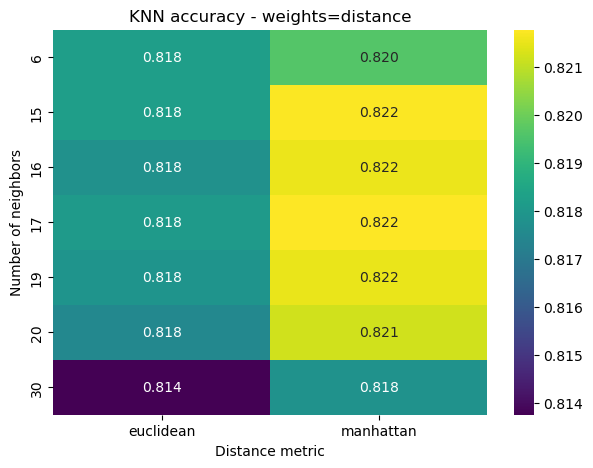

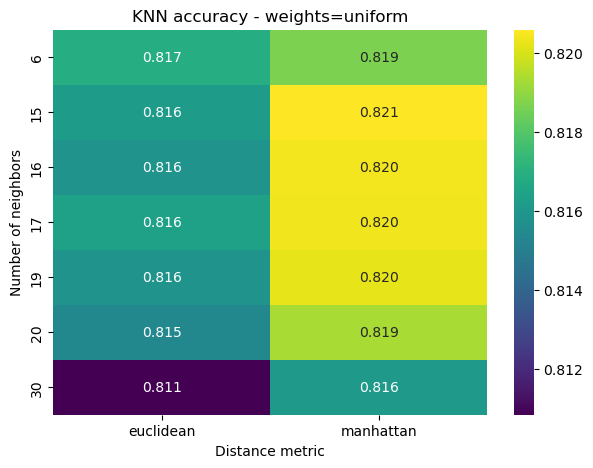

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert parameter columns to normal values
results["n_neighbors"] = results["param_n_neighbors"].astype(int)
results["weights"] = results["param_weights"]
results["metric"] = results["param_metric"]

# Plot each weight type separately
for weights in results["weights"].unique():

    subset = results[results["weights"] == weights]

    # Create a table:
    # rows = n_neighbors
    # columns = metric
    # values = mean CV accuracy
    pivot = subset.pivot(
        index="n_neighbors",
        columns="metric",
        values="mean_test_score"
    )

    # Create heatmap
    plt.figure(figsize=(7, 5))

    sns.heatmap(
        pivot,
        annot=True,       # Show accuracy values
        fmt=".3f",        # Show 3 decimal places
        cmap="viridis"
    )

    plt.title(f"KNN accuracy - weights={weights}")
    plt.xlabel("Distance metric")
    plt.ylabel("Number of neighbors")

    plt.show()